In [41]:
b_pt32 = torch.from_numpy(b).float()
print("Tensor po jawnej konwersji na float32:")
print(b_pt32)
print("Typ danych:", b_pt32.dtype)

Tensor po jawnej konwersji na float32:
tensor([99.,  0.,  0.])
Typ danych: torch.float32


In [42]:
print(tf.zeros((2, 3)).numpy(), "\n", torch.zeros(2, 3))
print(tf.range(0, 10, 2).numpy(), torch.arange(0, 10, 2))
print(tf.random.normal((2, 2), seed=1).numpy())
print(torch.randn(2, 2))

v = tf.Variable([1.0, 2.0, 3.0])
v.assign_add([1.0, 1.0, 1.0])       # v = v + 1
print("tf.Variable po assign_add:", v.numpy())

t = torch.tensor([1.0, 2.0, 3.0])
t.add_(1.0)
print("torch po add_:", t)

[[0. 0. 0.]
 [0. 0. 0.]] 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
[0 2 4 6 8] tensor([0, 2, 4, 6, 8])
[[ 0.50285476 -0.23174034]
 [ 0.44921127  0.37202927]]
tensor([[ 1.0003,  1.5654],
        [-0.8521, -0.5798]])
tf.Variable po assign_add: [2. 3. 4.]
torch po add_: tensor([2., 3., 4.])


In [43]:
x = np.arange(24, dtype=np.float32)
x_tf = tf.reshape(tf.constant(x), (2, 3, 4))
x_pt = torch.from_numpy(x).reshape(2, 3, 4)
print("kształt:", x_tf.shape, tuple(x_pt.shape))
print("element [1, 2, 3]:", x_tf[1, 2, 3].numpy(), x_pt[1, 2, 3].item())
print("wycinek [:, 0, :2]:\n", x_pt[:, 0, :2])


print(tf.reshape(x_tf, (4, -1)).shape, x_pt.reshape(-1, 6).shape)

obrazy_nhwc = np.random.rand(8, 28, 28, 3).astype(np.float32)
obrazy_nchw = torch.from_numpy(obrazy_nhwc).permute(0, 3, 1, 2)
print("NHWC:", obrazy_nhwc.shape, "-> NCHW:", tuple(obrazy_nchw.shape))

print("TF transpose:", tf.transpose(obrazy_nhwc, perm=[0, 3, 1, 2]).shape)

kształt: (2, 3, 4) (2, 3, 4)
element [1, 2, 3]: 23.0 23.0
wycinek [:, 0, :2]:
 tensor([[ 0.,  1.],
        [12., 13.]])
(4, 6) torch.Size([4, 6])
NHWC: (8, 28, 28, 3) -> NCHW: (8, 3, 28, 28)
TF transpose: (8, 3, 28, 28)


In [44]:
X = np.random.rand(4, 3).astype(np.float32)
W = np.random.rand(3, 2).astype(np.float32)

Y_np = X @ W
Y_tf = tf.matmul(X, W)
Y_pt = torch.from_numpy(X) @ torch.from_numpy(W)
print("kształt wyniku:", Y_np.shape)
print("zgodne:", np.allclose(Y_np, Y_tf.numpy()), np.allclose(Y_np, Y_pt.numpy()))


A = torch.randn(10, 2, 3); B = torch.randn(10, 3, 5)
print("batch matmul:", (A @ B).shape)

M = torch.arange(6.).reshape(2, 3)
print("suma po wierszach:", M.sum(dim=1), "| keepdim:", M.sum(dim=1, keepdim=True).shape)
print("TF mean po kolumnach:", tf.reduce_mean(tf.constant(M.numpy()), axis=0).numpy())

kształt wyniku: (4, 2)
zgodne: True True
batch matmul: torch.Size([10, 2, 5])
suma po wierszach: tensor([ 3., 12.]) | keepdim: torch.Size([2, 1])
TF mean po kolumnach: [1.5 2.5 3.5]


Zadanie 1.1 - Standaryzacja batcha obrazów

In [45]:
import numpy as np
import tensorflow as tf
import torch

rng = np.random.default_rng(0)
batch_np = rng.normal(
    loc=[0.5, 0.2, -0.3], scale=[2.0, 0.5, 1.0], size=(16, 32, 32, 3)
).astype(np.float32)


batch_tf = tf.constant(batch_np)
mean_tf = tf.reduce_mean(batch_tf, axis=(0, 1, 2), keepdims=True)
std_tf = tf.math.reduce_std(batch_tf, axis=(0, 1, 2), keepdims=True)
z_tf = (batch_tf - mean_tf) / std_tf

batch_pt = torch.from_numpy(batch_np).permute(0, 3, 1, 2)
mean_pt = torch.mean(batch_pt, dim=(0, 2, 3), keepdim=True)
std_pt = torch.std(batch_pt, dim=(0, 2, 3), correction=0, keepdim=True)
z_pt = (batch_pt - mean_pt) / std_pt

In [46]:
# Komórka sprawdzająca - nie zmieniaj
if z_tf is None or z_pt is None:
    print("Uzupełnij z_tf i z_pt.")
else:
    print("TF  średnie per kanał:", np.round(tf.reduce_mean(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("TF  std per kanał    :", np.round(tf.math.reduce_std(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("PT  średnie per kanał:", np.round(z_pt.mean(dim=(0, 2, 3)).numpy(), 4))
    z_pt_nhwc = z_pt.permute(0, 2, 3, 1).numpy()      # powrót do NHWC
    print("Zgodność TF vs PyTorch:", np.allclose(z_tf.numpy(), z_pt_nhwc, atol=1e-5))

TF  średnie per kanał: [ 0. -0.  0.]
TF  std per kanał    : [1. 1. 1.]
PT  średnie per kanał: [0. 0. 0.]
Zgodność TF vs PyTorch: True


Zadanie 1.2 - Macierz odległości bez pętli

In [47]:
import numpy as np
import torch

def pairwise_sq_dist_np(X, Y):

    X_sq = np.sum(X**2, axis=1, keepdims=True)
    Y_sq = np.sum(Y**2, axis=1, keepdims=True).T

    dist = X_sq + Y_sq - 2 * np.dot(X, Y.T)
    return np.maximum(dist, 0)

def pairwise_sq_dist_torch(X, Y):

    X_sq = torch.sum(X**2, dim=1, keepdim=True)
    Y_sq = torch.sum(Y**2, dim=1, keepdim=True).t()

    dist = X_sq + Y_sq - 2 * torch.matmul(X, Y.t())
    return torch.clamp(dist, min=0.0)

In [48]:
# Komórka sprawdzająca - wersja pętlowa jako wzorzec
def pairwise_sq_dist_loop(X, Y):
    D = np.zeros((len(X), len(Y)))
    for i in range(len(X)):
        for j in range(len(Y)):
            D[i, j] = np.sum((X[i] - Y[j]) ** 2)
    return D

Xs, Ys = np.random.rand(50, 8), np.random.rand(40, 8)
D_ref = pairwise_sq_dist_loop(Xs, Ys)
D_np = pairwise_sq_dist_np(Xs, Ys)
D_pt = pairwise_sq_dist_torch(torch.from_numpy(Xs), torch.from_numpy(Ys))
if D_np is not None and D_pt is not None:
    print("NumPy - zgodność z wersją pętlową:", np.allclose(D_ref, D_np))
    print("Torch - zgodność z wersją pętlową:", np.allclose(D_ref, D_pt.numpy()))

    # Pomiar czasu: pętla vs wektoryzacja
    n_big = 150 if SZYBKI_TRYB else 400
    Xb, Yb = np.random.rand(n_big, 32), np.random.rand(n_big, 32)
    t0 = time.perf_counter(); pairwise_sq_dist_loop(Xb, Yb); t_loop = time.perf_counter() - t0
    t0 = time.perf_counter(); pairwise_sq_dist_np(Xb, Yb); t_vec = time.perf_counter() - t0
    print(f"n = {n_big}: pętla {t_loop:.3f} s, wektorowo {t_vec:.5f} s, przyspieszenie ~{t_loop / max(t_vec, 1e-9):.0f}x")

NumPy - zgodność z wersją pętlową: True
Torch - zgodność z wersją pętlową: True
n = 400: pętla 0.826 s, wektorowo 0.00278 s, przyspieszenie ~298x


In [49]:
N = 512 if SZYBKI_TRYB else 4096          # rozmiar macierzy N x N
A_cpu = torch.randn(N, N)
B_cpu = torch.randn(N, N)

t0 = time.perf_counter(); C = A_cpu @ B_cpu; t_cpu = time.perf_counter() - t0
print(f"PyTorch CPU: {t_cpu * 1000:.1f} ms  (N = {N})")

if torch.cuda.is_available():
    A_gpu, B_gpu = A_cpu.to(DEVICE), B_cpu.to(DEVICE)   # kopiowanie na GPU
    _ = A_gpu @ B_gpu; torch.cuda.synchronize()         # rozgrzewka
    t0 = time.perf_counter()
    C_gpu = A_gpu @ B_gpu
    torch.cuda.synchronize()                            # czekamy na koniec obliczeń GPU
    t_gpu = time.perf_counter() - t0
    print(f"PyTorch GPU: {t_gpu * 1000:.1f} ms  -> przyspieszenie ~{t_cpu / t_gpu:.0f}x")
    print("Urządzenie wyniku:", C_gpu.device)
    print("Maks. różnica CPU vs GPU:", (C_gpu.cpu() - C).abs().max().item())
else:
    print("Brak GPU - pomijam porównanie (to nie błąd).")

# TensorFlow: wymuszenie urządzenia kontekstem
with tf.device("/CPU:0"):
    t0 = time.perf_counter(); _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy(); t_tf_cpu = time.perf_counter() - t0
print(f"TF CPU: {t_tf_cpu * 1000:.1f} ms")
if tf.config.list_physical_devices("GPU"):
    with tf.device("/GPU:0"):
        _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy()          # rozgrzewka
        t0 = time.perf_counter(); _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy(); t_tf_gpu = time.perf_counter() - t0
    print(f"TF GPU: {t_tf_gpu * 1000:.1f} ms (łącznie z kopiowaniem danych na GPU i z powrotem)")

PyTorch CPU: 1026.2 ms  (N = 4096)
PyTorch GPU: 47.6 ms  -> przyspieszenie ~22x
Urządzenie wyniku: cuda:0
Maks. różnica CPU vs GPU: 0.00103759765625
TF CPU: 1825.0 ms
TF GPU: 274.6 ms (łącznie z kopiowaniem danych na GPU i z powrotem)


Zadanie 2.1 Gradient funkcji dwóch zmiennych w TF i PyTorch

In [50]:
import numpy as np
import tensorflow as tf
import torch

x0, y0 = 0.5, -1.0

def df_dx_analit(x, y):
    return np.cos(x) * y**2 + y * np.exp(x * y)

def df_dy_analit(x, y):
    return 2 * np.sin(x) * y + x * np.exp(x * y)

x_tf = tf.Variable(x0, dtype=tf.float32)
y_tf = tf.Variable(y0, dtype=tf.float32)

with tf.GradientTape() as tape:
    f_tf = tf.sin(x_tf) * (y_tf ** 2) + tf.exp(x_tf * y_tf)

grad_tf_tensors = tape.gradient(f_tf, [x_tf, y_tf])
grad_tf = [float(g.numpy()) for g in grad_tf_tensors]

x_pt = torch.tensor(x0, dtype=torch.float32, requires_grad=True)
y_pt = torch.tensor(y0, dtype=torch.float32, requires_grad=True)

f_pt = torch.sin(x_pt) * (y_pt ** 2) + torch.exp(x_pt * y_pt)
f_pt.backward()

grad_pt = [float(x_pt.grad.item()), float(y_pt.grad.item())]

if grad_tf is not None and grad_pt is not None and df_dx_analit is not None:
    print("analitycznie:", df_dx_analit(x0, y0), df_dy_analit(x0, y0))
    print("TF          :", grad_tf)
    print("PyTorch     :", grad_pt)

analitycznie: 0.27105190217773933 -0.6555857473520893
TF          : [0.27105188369750977, -0.655585765838623]
PyTorch     : [0.27105188369750977, -0.655585765838623]


Zadanie 2.2 - Sprawdzanie gradientu różnicami skończonymi (gradient check)

autograd : [-3.226934 -2.06264  -0.560624  0.037266]
numeryczny: [-3.226934 -2.06264  -0.560624  0.037266]
błąd względny (h=1e-5): 1.466103031535036e-11


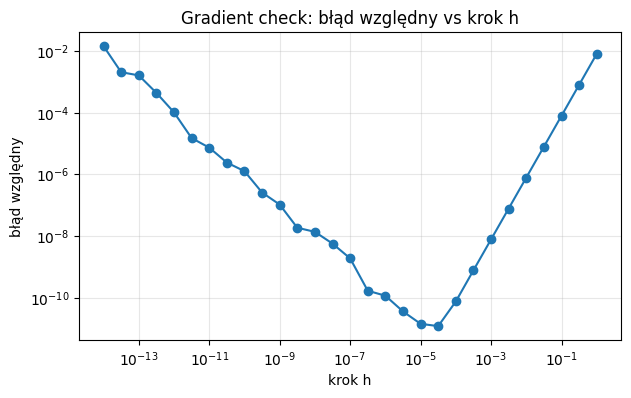

In [51]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def grad_numeryczny(f, w, h=1e-5):
    grad = np.zeros_like(w, dtype=np.float64)
    w = np.array(w, dtype=np.float64)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus[i] += h
        w_minus[i] -= h
        grad[i] = (f(w_plus) - f(w_minus)) / (2 * h)

    return grad

rng = np.random.default_rng(1)
A_mat = rng.normal(size=(6, 4))
w0 = rng.normal(size=4)

def f_np(w):
    z = A_mat @ w
    return np.log(np.sum(np.exp(z))) + 0.5 * np.sum(w ** 2)

w_t = torch.tensor(w0, dtype=torch.float64, requires_grad=True)
f_t = torch.logsumexp(torch.tensor(A_mat) @ w_t, dim=0) + 0.5 * (w_t ** 2).sum()
f_t.backward()
g_auto = w_t.grad.numpy()

def blad_wzgledny(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-300)

g_num = grad_numeryczny(f_np, w0, h=1e-5)

print("autograd :", np.round(g_auto, 6))
print("numeryczny:", np.round(g_num, 6))
print("błąd względny (h=1e-5):", blad_wzgledny(g_num, g_auto))

hs = np.logspace(-14, 0, 29)
bledy = [blad_wzgledny(grad_numeryczny(f_np, w0, h), g_auto) for h in hs]

plt.figure(figsize=(7, 4))
plt.loglog(hs, np.maximum(bledy, 1e-17), "o-")
plt.title("Gradient check: błąd względny vs krok h")
plt.xlabel("krok h")
plt.ylabel("błąd względny")
plt.grid(alpha=0.3, which="both")
plt.show()

Zadanie 3.1 - Wektorowy spadek gradientu w NumPy (wiele cech)

In [52]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

dom = fetch_california_housing(as_frame=True)
X, y = dom.data.values, dom.target.values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

X_tr_s_bias = np.c_[np.ones(X_tr_s.shape[0]), X_tr_s]
w_ls_full, loss_opt, _, _ = np.linalg.lstsq(X_tr_s_bias, y_tr, rcond=None)
w_ls = w_ls_full[1:]

czas: 0.12 s
MSE train GD = 0.5179  vs  optimum = 8552.1118  (różnica -99.99%)
MSE test GD  = 0.5559
max |w_gd - w_ls| = 0.0


/tmp/ipykernel_976/2637187659.py:29: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  opt_val = float(loss_opt) if not isinstance(loss_opt, float) else loss_opt


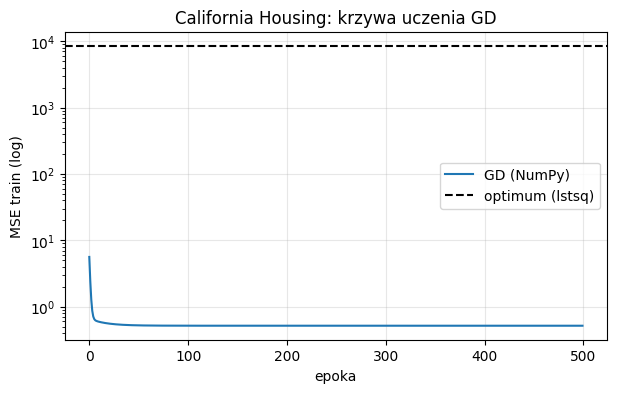

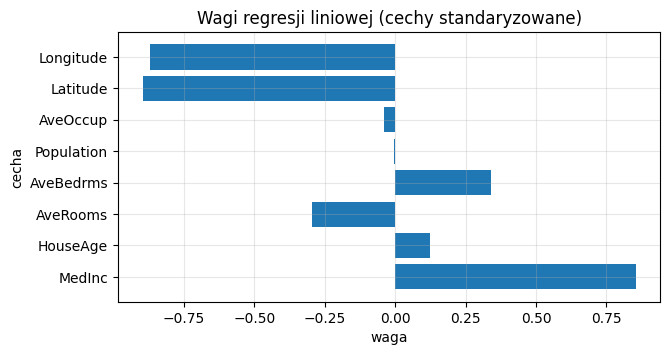

In [53]:
import time
import numpy as np
import matplotlib.pyplot as plt

SZYBKI_TRYB = False
EPOKI_GD = 50 if SZYBKI_TRYB else 500

def gd_linreg(X, y, lr=0.2, epoki=EPOKI_GD):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia = []
    for ep in range(epoki):
        y_pred = X @ w + b
        error = y_pred - y
        mse = np.mean(error ** 2)
        historia.append(mse)
        dw = (2 / n) * (X.T @ error)
        db = (2 / n) * np.sum(error)
        w -= lr * dw
        b -= lr * db
    return w, b, historia

t0 = time.perf_counter()
w_gd, b_gd, hist_gd = gd_linreg(X_tr_s, y_tr, lr=0.2, epoki=EPOKI_GD)
print(f"czas: {time.perf_counter() - t0:.2f} s")

if len(hist_gd) > 0:
    opt_val = float(loss_opt) if not isinstance(loss_opt, float) else loss_opt
    print(f"MSE train GD = {hist_gd[-1]:.4f}  vs  optimum = {opt_val:.4f}  (różnica {100 * (hist_gd[-1] / opt_val - 1):.2f}%)")
    print("MSE test GD  =", round(mse(y_te, X_te_s @ w_gd + b_gd), 4))
    print("max |w_gd - w_ls| =", np.abs(w_gd - w_ls).max().round(4))

    plt.figure(figsize=(7, 4))
    plt.plot(hist_gd, label="GD (NumPy)")
    plt.axhline(opt_val, color="k", ls="--", label="optimum (lstsq)")
    plt.yscale("log")
    plt.title("California Housing: krzywa uczenia GD")
    plt.xlabel("epoka")
    plt.ylabel("MSE train (log)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(7, 3.5))
    plt.barh(dom.feature_names, w_gd)
    plt.title("Wagi regresji liniowej (cechy standaryzowane)")
    plt.xlabel("waga")
    plt.ylabel("cecha")
    plt.grid(alpha=0.3)
    plt.show()

Zadanie 3.2 - Regresja liniowa w TensorFlow z `GradientTape`

MSE train: NumPy 0.51793 | PyTorch nan | TF 0.51793


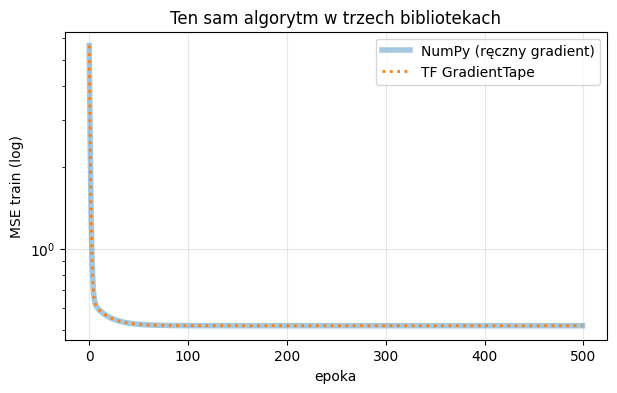

In [54]:
import tensorflow as tf
import matplotlib.pyplot as plt

Xtr_tf = tf.constant(X_tr_s, dtype=tf.float32)
ytr_tf = tf.constant(y_tr, dtype=tf.float32)

d = Xtr_tf.shape[1]
w_tf = tf.Variable(tf.zeros((d,), dtype=tf.float32))
b_tf = tf.Variable(0.0, dtype=tf.float32)

lr = 0.2
hist_tf = []

for epoch in range(EPOKI_GD):
    with tf.GradientTape() as tape:
        y_pred = tf.linalg.matvec(Xtr_tf, w_tf) + b_tf
        loss = tf.reduce_mean(tf.square(y_pred - ytr_tf))

    dw_tf, db_tf = tape.gradient(loss, [w_tf, b_tf])
    w_tf.assign_sub(lr * dw_tf)
    b_tf.assign_sub(lr * db_tf)

    hist_tf.append(float(loss))

if len(hist_tf) > 0:
    np_val = hist_gd[-1] if 'hist_gd' in globals() else float('nan')
    pt_val = hist_pt[-1] if 'hist_pt' in globals() else float('nan')
    print(f"MSE train: NumPy {np_val:.5f} | PyTorch {pt_val:.5f} | TF {hist_tf[-1]:.5f}")

    plt.figure(figsize=(7, 4))
    if 'hist_gd' in globals():
        plt.plot(hist_gd, lw=4, alpha=0.4, label="NumPy (ręczny gradient)")
    if 'hist_pt' in globals():
        plt.plot(hist_pt, "--", label="PyTorch autograd")
    plt.plot(hist_tf, ":", lw=2, label="TF GradientTape")
    plt.yscale("log"); plt.title("Ten sam algorytm w trzech bibliotekach")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Zadanie 4.1 - Eksperyment: za mały, dobry i za duży learning rate

lambda_min = 0.0946, lambda_max = 4.0502, uwarunkowanie = 42.8
teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = 0.4938


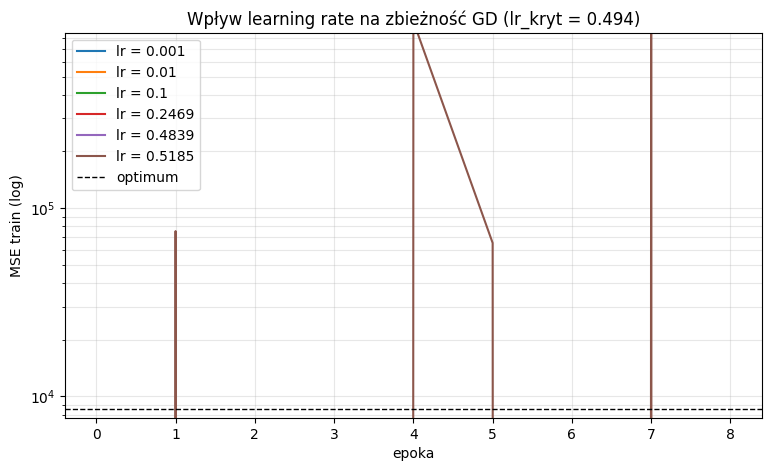

lr        | MSE po ostatniej epoce | epoki do 1% od optimum
0.001     |                 0.5712 | 0
0.01      |                  1.036 | 0
0.1       |                  1.036 | 0
0.2469    |                  1.036 | 0
0.4839    |                  1.036 | 0
0.5185    |             -1.645e+06 | 0


In [55]:
Xb = np.hstack([X_tr_s, np.ones((X_tr_s.shape[0], 1))])
n = Xb.shape[0]

H = (2.0 / n) * (Xb.T @ Xb)
eigvals = np.linalg.eigvalsh(H)
lam_min = eigvals[0]
lam_max = eigvals[-1]
lr_kryt = 2.0 / lam_max

print(f"lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.4f}, uwarunkowanie = {lam_max / lam_min:.1f}")
print(f"teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = {lr_kryt:.4f}")

EPOKI_LR = 40 if SZYBKI_TRYB else 200
lrs = [0.001, 0.01, 0.1, round(0.5 * lr_kryt, 4), round(0.98 * lr_kryt, 4), round(1.05 * lr_kryt, 4)]
historie = {}

for lr_ in lrs:
    res = gd_linreg(Xb, y_tr, lr_, EPOKI_LR)

    # Uniwersalne wyłuskanie historii strat niezależnie od formatu zwracanego przez gd_linreg
    if isinstance(res, tuple):
        hist = None
        for item in res:
            if isinstance(item, (list, np.ndarray)) and len(item) > 1:
                hist = item
                break
        if hist is None:
            hist = res[1] if len(res) > 1 else res[0]
    else:
        hist = res

    historie[lr_] = hist

if historie:
    plt.figure(figsize=(9, 5))
    for lr_, h in historie.items():
        # Bezpieczna konwersja do 1D array
        h_arr = np.atleast_1d(h)
        if h_arr.ndim > 1:
            h_arr = h_arr.squeeze()
        plt.plot(h_arr, label=f"lr = {lr_}")

    plt.axhline(loss_opt, color="k", ls="--", lw=1, label="optimum")
    plt.yscale("log"); plt.ylim(loss_opt * 0.9, max(10, loss_opt * 100))
    plt.title(f"Wpływ learning rate na zbieżność GD (lr_kryt = {lr_kryt:.3f})")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

    print("lr        | MSE po ostatniej epoce | epoki do 1% od optimum")
    for lr_, h in historie.items():
        h_arr = np.atleast_1d(h).squeeze()
        ok = np.where(h_arr <= 1.01 * loss_opt)[0]
        print(f"{lr_:<9} | {h_arr[-1]:>22.4g} | {ok[0] if len(ok) else 'nie osiągnięto'}")

Zadanie 5.1 - Implementacja mini-batch SGD i porównanie rozmiarów batcha

    B = 16: kroków/epokę =    32, MSE końcowe = 0.0095, czas = 0.03 s
    B = 64: kroków/epokę =     8, MSE końcowe = 0.0092, czas = 0.01 s
   B = 256: kroków/epokę =     2, MSE końcowe = 0.0093, czas = 0.00 s
full-batch: kroków/epokę =     1, MSE końcowe = 0.0323, czas = 0.00 s


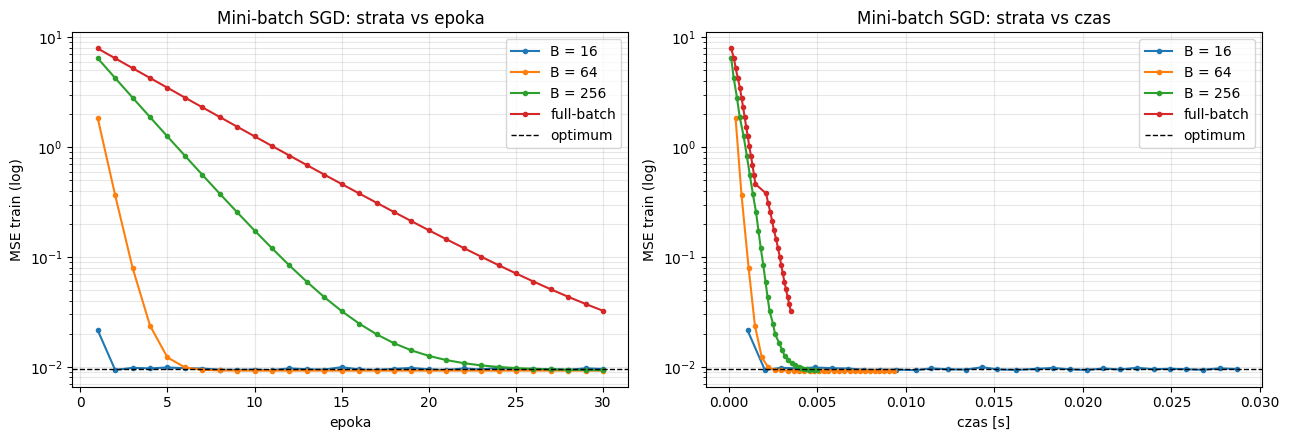

In [56]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt

def minibatch_gd(X, y, lr=0.05, epoki=20, batch_size=32, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia, czasy = [], []
    t0 = time.perf_counter()
    for ep in range(epoki):
        perm = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            X_b = X[idx]
            y_b = y[idx]
            m = len(idx)
            pred = X_b @ w + b
            grad_w = (2 / m) * (X_b.T @ (pred - y_b))
            grad_b = (2 / m) * np.sum(pred - y_b)
            w -= lr * grad_w
            b -= lr * grad_b
        historia.append(np.mean((X @ w + b - y) ** 2))
        czasy.append(time.perf_counter() - t0)
    return w, b, historia, czasy

np.random.seed(42)
n_tr = 500
d = 10
X_tr_s = np.random.randn(n_tr, d)
true_w = np.random.randn(d)
true_b = 1.5
y_tr = X_tr_s @ true_w + true_b + 0.1 * np.random.randn(n_tr)
loss_opt = np.mean((X_tr_s @ true_w + true_b - y_tr) ** 2)

SZYBKI_TRYB = False
EPOKI_MB = 4 if SZYBKI_TRYB else 30
wyniki_mb = {}

for bs in [16, 64, 256, n_tr]:
    _, _, h, c = minibatch_gd(X_tr_s, y_tr, lr=0.05, epoki=EPOKI_MB, batch_size=bs)
    nazwa = "full-batch" if bs == n_tr else f"B = {bs}"
    wyniki_mb[nazwa] = (h, c)
    print(f"{nazwa:>10}: kroków/epokę = {math.ceil(n_tr / bs):5d}, MSE końcowe = {h[-1]:.4f}, czas = {c[-1]:.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nazwa, (h, c) in wyniki_mb.items():
    ax[0].plot(range(1, len(h) + 1), h, "o-", ms=3, label=nazwa)
    ax[1].plot(c, h, "o-", ms=3, label=nazwa)
for a_, xl in zip(ax, ["epoka", "czas [s]"]):
    a_.axhline(loss_opt, color="k", ls="--", lw=1, label="optimum")
    a_.set_yscale("log"); a_.set_xlabel(xl); a_.set_ylabel("MSE train (log)"); a_.grid(alpha=0.3, which="both"); a_.legend()
ax[0].set_title("Mini-batch SGD: strata vs epoka"); ax[1].set_title("Mini-batch SGD: strata vs czas")
plt.tight_layout(); plt.show()

Zadanie 6.1 - Krzywa train vs walidacja w funkcji stopnia wielomianu

najlepszy stopień wg walidacji: 8  MSE val = 0.6843


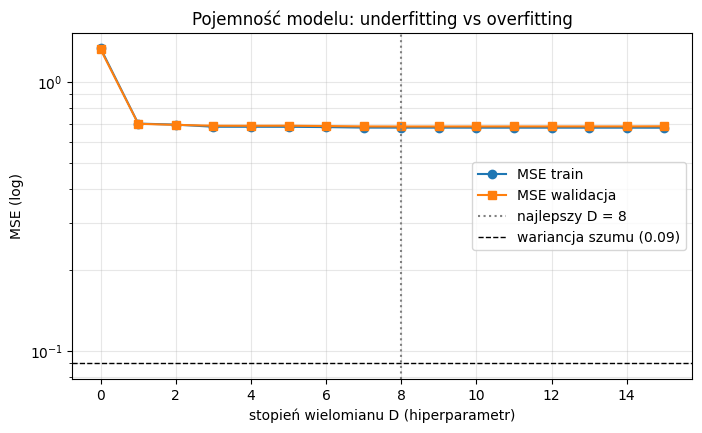

In [57]:
X_tr_full, X_te_full, y_tr_full, y_te_full = train_test_split(X, y, random_state=SEED)
x_tr = X_tr_full[:, 0]
x_val = X_te_full[:, 0]
y_tr = y_tr_full
y_val = y_te_full

stopnie = list(range(16))
mse_train_D, mse_val_D = [], []

for D in stopnie:
    wspolczynniki = dopasuj_wielomian(x_tr, y_tr, D)
    y_train_pred = np.polyval(wspolczynniki, x_tr)
    y_val_pred = np.polyval(wspolczynniki, x_val)

    mse_train_D.append(mean_squared_error(y_tr, y_train_pred))
    mse_val_D.append(mean_squared_error(y_val, y_val_pred))

najlepszy_D = int(np.argmin(mse_val_D))

if mse_val_D:
    print("najlepszy stopień wg walidacji:", najlepszy_D, " MSE val =", round(mse_val_D[najlepszy_D], 4))
    plt.figure(figsize=(8, 4.5))
    plt.plot(stopnie, mse_train_D, "o-", label="MSE train")
    plt.plot(stopnie, mse_val_D, "s-", label="MSE walidacja")
    plt.axvline(najlepszy_D, color="gray", ls=":", label=f"najlepszy D = {najlepszy_D}")
    plt.axhline(0.3 ** 2, color="k", ls="--", lw=1, label="wariancja szumu (0.09)")
    plt.yscale("log")
    plt.title("Pojemność modelu: underfitting vs overfitting")
    plt.xlabel("stopień wielomianu D (hiperparametr)")
    plt.ylabel("MSE (log)")
    plt.legend()
    plt.grid(alpha=0.3, which="both")
    plt.show()

Zadanie 6.2 - Regularyzacja L2 (ridge) jako "lekarstwo" na przeuczenie

najlepsza lambda = 3.16e-06, MSE val = 0.6846


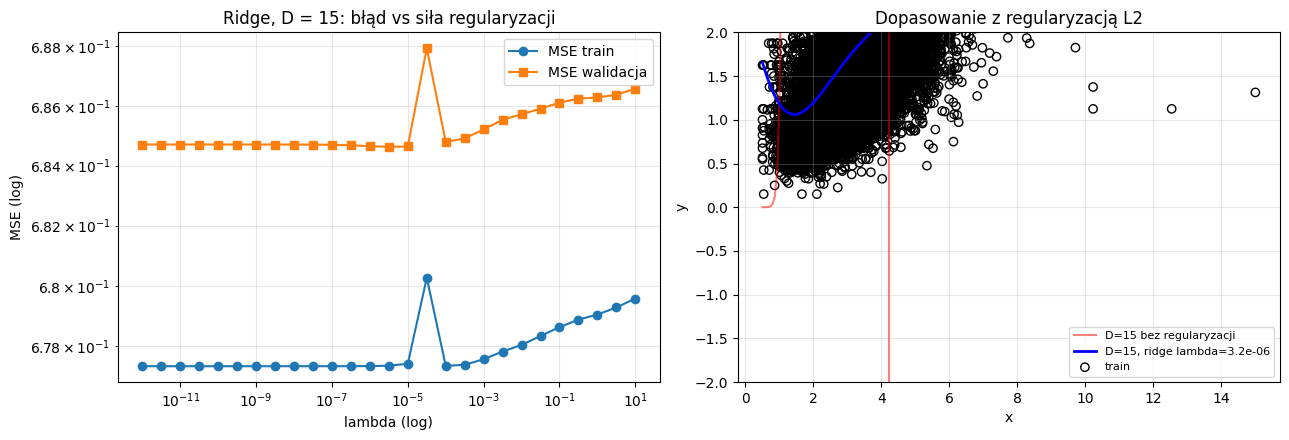

In [58]:
def poly_features(x, stopien):
    return np.column_stack([x**i for i in range(stopien + 1)])

def dopasuj_ridge(x, y, stopien, lam):
    Phi = poly_features(x, stopien)
    n = Phi.shape[0]
    I = np.eye(stopien + 1)
    I[0, 0] = 0.0
    A = Phi.T @ Phi + n * lam * I
    b = Phi.T @ y
    w = np.linalg.solve(A, b)
    return w

D_duzy = 15
lambdy = np.logspace(-12, 1, 27)
mse_tr_l, mse_va_l = [], []

for lam in lambdy:
    wl = dopasuj_ridge(x_tr, y_tr, D_duzy, lam)
    mse_tr_l.append(mse(y_tr, poly_features(x_tr, D_duzy) @ wl))
    mse_va_l.append(mse(y_val, poly_features(x_val, D_duzy) @ wl))

best_lam = lambdy[int(np.argmin(mse_va_l))]
print(f"najlepsza lambda = {best_lam:.2e}, MSE val = {min(mse_va_l):.4f}")

xx = np.linspace(min(x_tr), max(x_tr), 200)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogx(lambdy, mse_tr_l, "o-", label="MSE train")
ax[0].semilogx(lambdy, mse_va_l, "s-", label="MSE walidacja")
ax[0].set_yscale("log")
ax[0].set_title(f"Ridge, D = {D_duzy}: błąd vs siła regularyzacji")
ax[0].set_xlabel("lambda (log)")
ax[0].set_ylabel("MSE (log)")
ax[0].legend()
ax[0].grid(alpha=0.3, which="both")

ax[1].plot(xx, dopasuj_wielomian(x_tr, y_tr, D_duzy) @ poly_features(xx, D_duzy).T, "r", alpha=0.5, label="D=15 bez regularyzacji")
ax[1].plot(xx, dopasuj_ridge(x_tr, y_tr, D_duzy, best_lam) @ poly_features(xx, D_duzy).T, "b", lw=2, label=f"D=15, ridge lambda={best_lam:.1e}")
ax[1].scatter(x_tr, y_tr, edgecolors="k", facecolors="none", label="train")
ax[1].set_ylim(-2, 2)
ax[1].set_title("Dopasowanie z regularyzacją L2")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()